# 4: Temporal Change Detection
We reuse the trained ResNet18 backbone as a feature extractor (stripping the final classification layer) to obtain 512-dimensional embeddings. We then compute **Cosine Similarity** to detect temporal changes and establish dynamic thresholds.

In [1]:
import os
import sys
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
from sklearn.metrics import roc_curve, auc

sys.path.append(str(Path.cwd().parent))

from configs.paths import EUROSAT_DIR, OUTPUTS_DIR
from data.dataset_loader import SatelliteDatasetLoader
from inference.change_detector import TemporalChangeDetector

# Load data configuration to determine classes
loader = SatelliteDatasetLoader(EUROSAT_DIR, split_type='random')
num_classes = len(loader.classes)

# Initialize Detector using best weights from Phase 6
model_path = OUTPUTS_DIR / 'resnet18_best.pth'
detector = TemporalChangeDetector(model_path=model_path, num_classes=num_classes)

2026-07-19 18:49:19,611 - INFO - DatasetLoader - Loaded dataset from D:\Main_Project_PeeyushVerma\data\datasets\eurosat\EuroSAT containing 27000 images across 10 classes.
d:\Main_Project_PeeyushVerma\models\feature_extractor.py:30: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control o

## 1. Simulate Image Pairs
Since standard datasets (like EuroSAT) don't have explicit "before/after" temporal pairs mapping the exact same geographic polygon, we will simulate pairs to evaluate our embedding space:
- **Label `0`**: No Change (Two different images sampled from the *same* class)
- **Label `1`**: Change (Two different images sampled from *different* classes)

In [2]:
def get_image_paths_by_class(dataset_dir):
    class_paths = {}
    for cls_name in os.listdir(dataset_dir):
        cls_dir = os.path.join(dataset_dir, cls_name)
        if os.path.isdir(cls_dir):
            class_paths[cls_name] = [os.path.join(cls_dir, f) for f in os.listdir(cls_dir) if f.endswith(('.jpg', '.png'))]
    return class_paths

class_paths = get_image_paths_by_class(EUROSAT_DIR)
classes = list(class_paths.keys())

pairs = []
labels = []
num_pairs_per_type = 200 # Total 400 simulated pairs

# Generate "No Change" Pairs (Same semantic class)
for _ in range(num_pairs_per_type):
    cls = random.choice(classes)
    img1_path, img2_path = random.sample(class_paths[cls], 2)
    pairs.append((img1_path, img2_path))
    labels.append(0) 
    
# Generate "Change" Pairs (Different semantic classes)
for _ in range(num_pairs_per_type):
    cls1, cls2 = random.sample(classes, 2)
    img1_path = random.choice(class_paths[cls1])
    img2_path = random.choice(class_paths[cls2])
    pairs.append((img1_path, img2_path))
    labels.append(1)

print(f"Generated {len(pairs)} simulated temporal pairs.")

Generated 400 simulated temporal pairs.


## 2. Extract Embeddings & Compute Similarity

In [3]:
similarities = []
from tqdm import tqdm

for img1_path, img2_path in tqdm(pairs, desc="Calculating Similarities"):
    img1 = Image.open(img1_path).convert('RGB')
    img2 = Image.open(img2_path).convert('RGB')
    sim = detector.calculate_similarity(img1, img2)
    similarities.append(sim)

Calculating Similarities:   0%|          | 0/400 [00:00<?, ?it/s]2026-07-19 18:49:27,651 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.871641
2026-07-19 18:49:27,701 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.859980
Calculating Similarities:   0%|          | 2/400 [00:00<00:25, 15.58it/s]2026-07-19 18:49:27,751 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.767120
2026-07-19 18:49:27,800 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.824023
2026-07-19 18:49:27,857 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.738588
Calculating Similarities:   1%|▏         | 5/400 [00:00<00:22, 17.91it/s]2026-07-19 18:49:27,900 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.889425
2026-07-19 18:49:27,947 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.967463
2026-07-19 18:49:27,989 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.601475
Calculating Similarities:   2

## 3. Threshold Selection via ROC Curve
Cosine similarity outputs 1.0 for identical embeddings and lower values for different embeddings. 
To plot a standard ROC curve, we invert the metric to a distance: `distance = 1 - similarity`. High distance predicts "Change" (Positive Class).

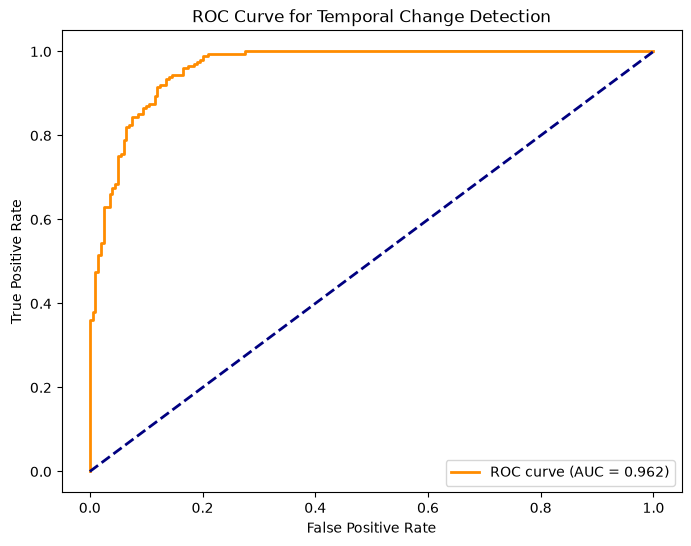

Optimal Cosine Similarity Threshold: 0.6533


In [4]:
distances = [1.0 - s for s in similarities]

fpr, tpr, thresholds = roc_curve(labels, distances)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Temporal Change Detection')
plt.legend(loc="lower right")
plt.show()

# Find Optimal Threshold using Youden's J statistic
optimal_idx = np.argmax(tpr - fpr)
optimal_distance_threshold = thresholds[optimal_idx]
optimal_sim_threshold = 1.0 - optimal_distance_threshold
print(f"Optimal Cosine Similarity Threshold: {optimal_sim_threshold:.4f}")

## 4. Similarity Distribution Analysis

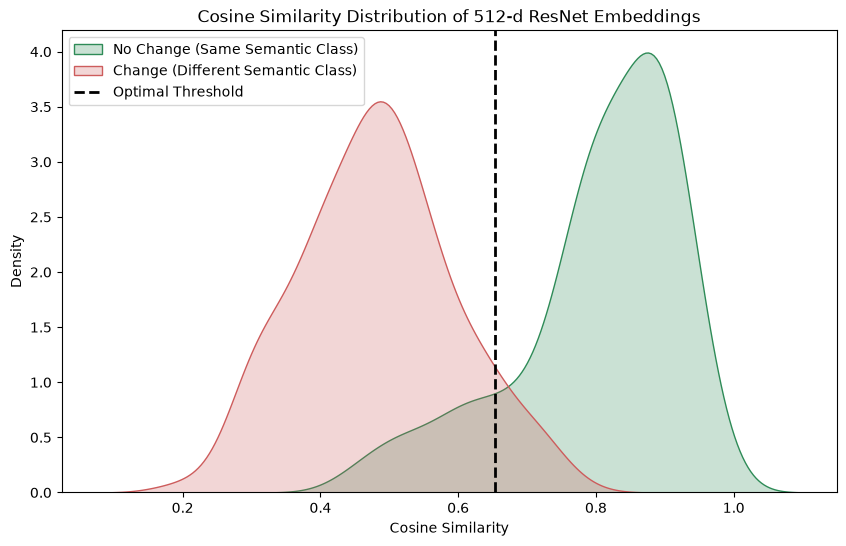

In [5]:
sims_no_change = [similarities[i] for i in range(len(labels)) if labels[i] == 0]
sims_change = [similarities[i] for i in range(len(labels)) if labels[i] == 1]

plt.figure(figsize=(10, 6))
sns.kdeplot(sims_no_change, label='No Change (Same Semantic Class)', fill=True, color='seagreen')
sns.kdeplot(sims_change, label='Change (Different Semantic Class)', fill=True, color='indianred')
plt.axvline(x=optimal_sim_threshold, color='black', linestyle='--', lw=2, label='Optimal Threshold')
plt.xlabel('Cosine Similarity')
plt.title('Cosine Similarity Distribution of 512-d ResNet Embeddings')
plt.legend()
plt.show()

## 5. Visual Examples: Heatmaps & Difference Maps
Displaying 5 concrete examples: 2 No Change pairs, and 3 Change pairs.

2026-07-19 18:50:00,551 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.871641



=================== NO CHANGE EXAMPLES ===================


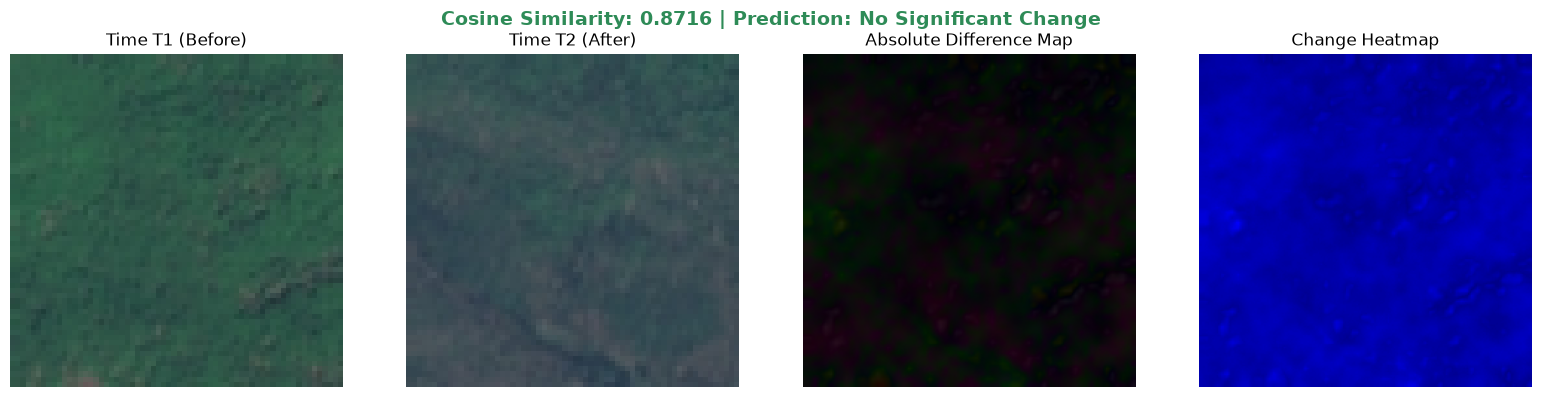

2026-07-19 18:50:00,887 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.859980


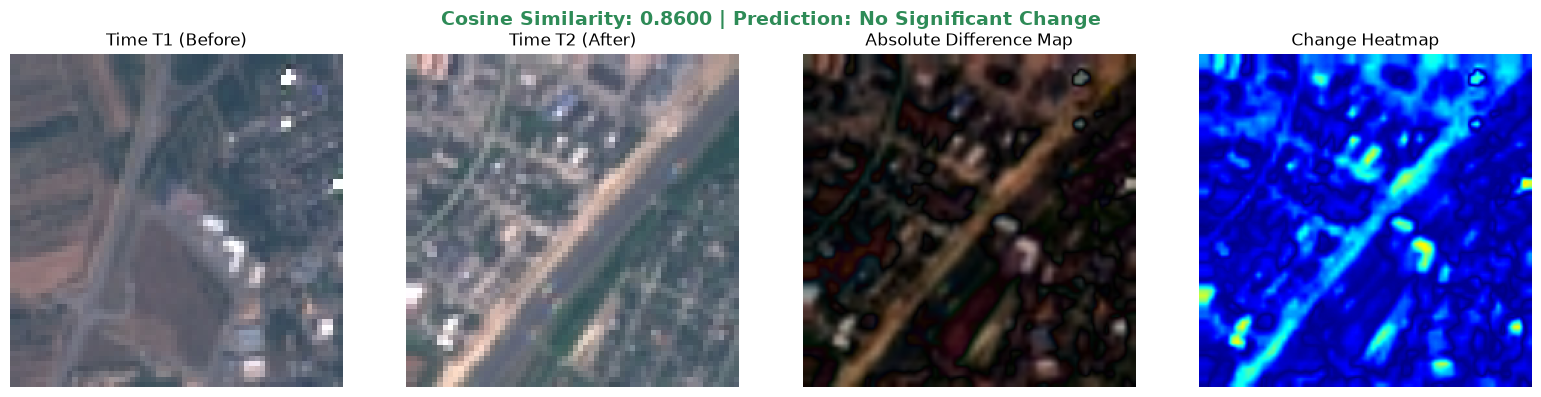

2026-07-19 18:50:01,315 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.582030



===================== CHANGE EXAMPLES ====================


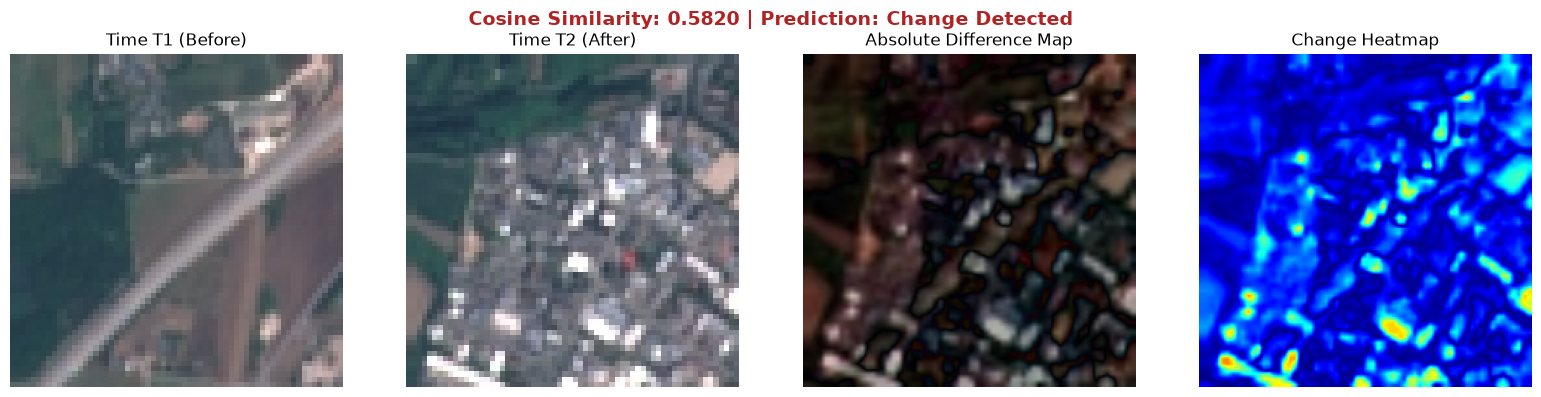

2026-07-19 18:50:01,611 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.531410


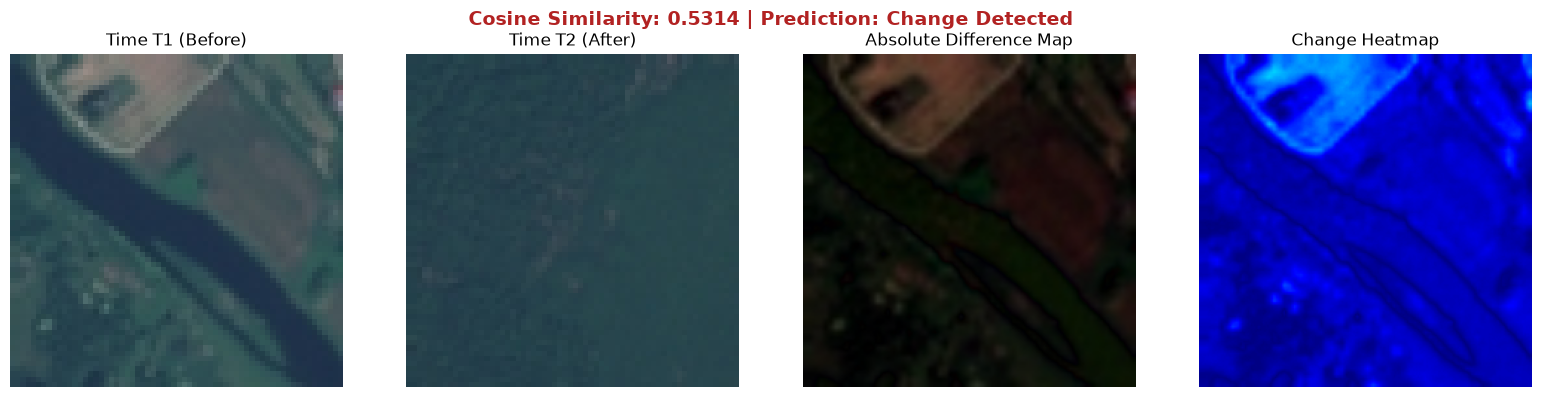

2026-07-19 18:50:01,907 - INFO - TemporalChangeDetector - Computed Cosine Similarity: 0.461583


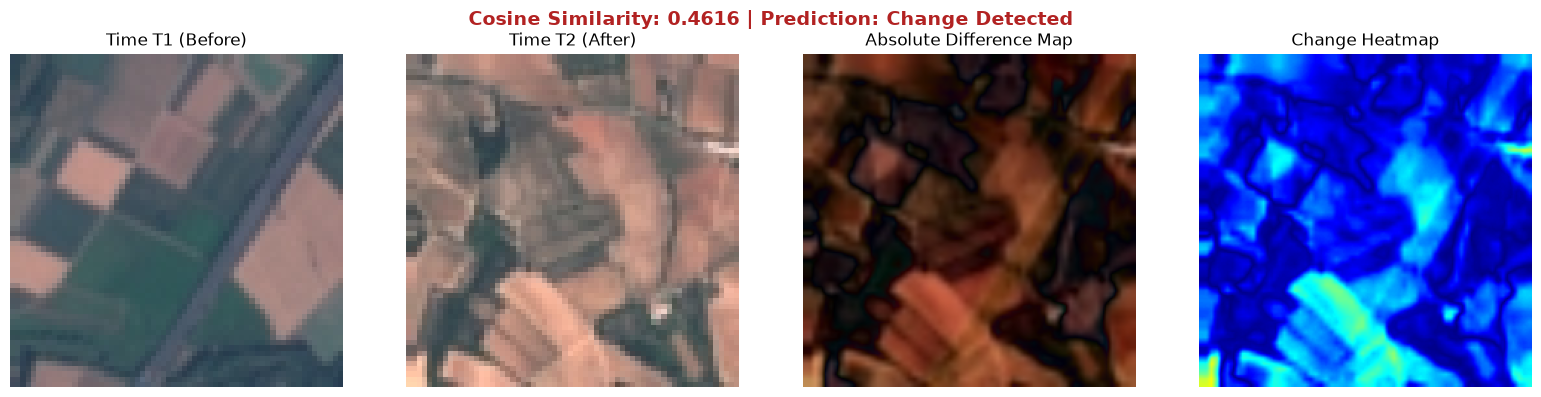

In [6]:
def show_change_example(img1_path, img2_path):
    img1 = Image.open(img1_path).convert('RGB')
    img2 = Image.open(img2_path).convert('RGB')
    
    sim = detector.calculate_similarity(img1, img2)
    diff, heatmap = detector.generate_difference_map(img1, img2)
    
    prediction = "Change Detected" if sim < optimal_sim_threshold else "No Significant Change"
    color = "#B22222" if prediction == "Change Detected" else "#2E8B57"
    
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(img1)
    axes[0].set_title("Time T1 (Before)")
    axes[0].axis('off')
    
    axes[1].imshow(img2)
    axes[1].set_title("Time T2 (After)")
    axes[1].axis('off')
    
    axes[2].imshow(diff)
    axes[2].set_title("Absolute Difference Map")
    axes[2].axis('off')
    
    axes[3].imshow(heatmap)
    axes[3].set_title("Change Heatmap")
    axes[3].axis('off')
    
    plt.suptitle(f"Cosine Similarity: {sim:.4f} | Prediction: {prediction}", color=color, fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()

print("\n=================== NO CHANGE EXAMPLES ===================")
show_change_example(pairs[0][0], pairs[0][1])
show_change_example(pairs[1][0], pairs[1][1])

print("\n===================== CHANGE EXAMPLES ====================")
show_change_example(pairs[num_pairs_per_type][0], pairs[num_pairs_per_type][1])
show_change_example(pairs[num_pairs_per_type+1][0], pairs[num_pairs_per_type+1][1])
show_change_example(pairs[num_pairs_per_type+2][0], pairs[num_pairs_per_type+2][1])